# Heart Health Analysis — Step-by-Step Python Workbook

**Project Goal:** Analyze patient health indicators to identify patterns associated with heart disease and communicate findings that may support prevention and early intervention.

1. Open this notebook in Jupyter Notebook
2. Keep `heart.csv` in the same folder as this notebook, upload it through the Files panel.
3. Run each cell from top to bottom using **Shift + Enter**.
4. Read the explanation under each section and save your charts/results for your report.

## 1. Set up Python libraries

In [181]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the dataset

In [182]:
df = pd.read_csv("C:/Users/ankus/Downloads/JobAaj Project/EDA Project/EDA03 Project/heart.csv")

print("Dataset loaded successfully.")
print("Rows and columns:", df.shape)
display(df.head())

Dataset loaded successfully.
Rows and columns: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


## 3. Understand the dataset

In [183]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [184]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


## 4. Data quality checks

In [185]:
display(df.isna().sum().to_frame("missing_values"))

print("Duplicate rows:", df.duplicated().sum())

for col in df.columns:
    print(f"{col}: {sorted(df[col].dropna().unique().tolist())}")

,missing_values
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


Duplicate rows: 723
age: [29, 34, 35, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 74, 76, 77]
sex: [0, 1]
cp: [0, 1, 2, 3]
trestbps: [94, 100, 101, 102, 104, 105, 106, 108, 110, 112, 114, 115, 117, 118, 120, 122, 123, 124, 125, 126, 128, 129, 130, 132, 134, 135, 136, 138, 140, 142, 144, 145, 146, 148, 150, 152, 154, 155, 156, 160, 164, 165, 170, 172, 174, 178, 180, 192, 200]
chol: [126, 131, 141, 149, 157, 160, 164, 166, 167, 168, 169, 172, 174, 175, 176, 177, 178, 180, 182, 183, 184, 185, 186, 187, 188, 192, 193, 195, 196, 197, 198, 199, 200, 201, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 273, 274, 275,

## Remove exact duplicate rows

In [186]:
data = df.copy()

### Check suspicious ranges

In [187]:
range_checks = {
    "age": (0, 120),
    "trestbps": (50, 300),
    "chol": (50, 700),
    "thalach": (40, 250),
    "oldpeak": (-5, 10)
}
for col, (low, high) in range_checks.items():
    if col in data.columns:
        flagged = data[~data[col].between(low, high)]
        print(f"{col}: {len(flagged)} row(s) outside review range")

age: 0 row(s) outside review range
trestbps: 0 row(s) outside review range
chol: 0 row(s) outside review range
thalach: 0 row(s) outside review range
oldpeak: 0 row(s) outside review range


## Basic Level Questions

## Basic Q1. What is the average age of patients?

In [188]:
avg_age = data["age"].mean()
print(f"Average patient age: {avg_age:.2f} years")

Average patient age: 54.43 years


## Basic Q2. What is the gender/sex distribution?

In [189]:
sex_counts = data["sex"].map({1: "Male (coded 1)", 0: "Female (coded 0)"}).value_counts()
sex_percent = data["sex"].map({1: "Male (coded 1)", 0: "Female (coded 0)"}).value_counts(normalize=True).mul(100)
display(pd.DataFrame({"count": sex_counts, "percentage": sex_percent.round(2)}))

,count,percentage
sex,,
Male (coded 1),713,69.56
Female (coded 0),312,30.44


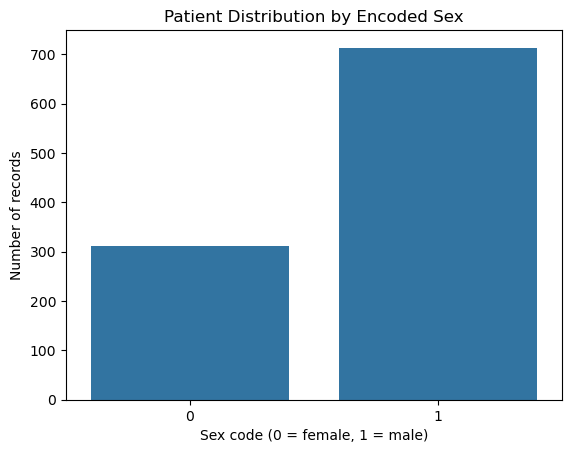

In [190]:
sns.countplot(data=data, x="sex")
plt.title("Patient Distribution by Encoded Sex")
plt.xlabel("Sex code (0 = female, 1 = male)")
plt.ylabel("Number of records")
plt.show()

## Basic Q3. What is the average resting blood pressure?

In [191]:
print(f"Average resting blood pressure: {data['trestbps'].mean():.2f}")

Average resting blood pressure: 131.61


## Basic Q4. How many patients have `fbs = 1`?

In [192]:
print("Records with fbs = 1:", int((data["fbs"] == 1).sum()))

Records with fbs = 1: 153


## Basic Q5. What are the counts for each chest-pain type?

,count
cp category,
0,497
1,167
2,284
3,77


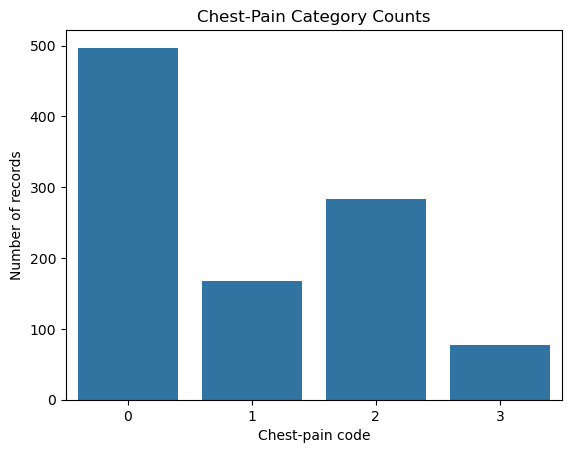

In [193]:
display(data["cp"].value_counts().sort_index().rename_axis("cp category").to_frame("count"))
sns.countplot(data=data, x="cp", order=sorted(data["cp"].dropna().unique()))
plt.title("Chest-Pain Category Counts")
plt.xlabel("Chest-pain code")
plt.ylabel("Number of records")
plt.show()

## Basic Q6. What is the maximum `thalach` value?

In [194]:
print("Maximum maximum-heart-rate value (thalach):", data["thalach"].max())

Maximum maximum-heart-rate value (thalach): 202


## Basic Q7. What percentage of records have exercise-induced angina (`exang = 1`)?

In [195]:
exang_pct = (data["exang"].eq(1).mean()) * 100
print(f"Records with exang = 1: {exang_pct:.2f}%")

Records with exang = 1: 33.66%


## Basic Q8. What is the average cholesterol level?

In [196]:
print(f"Average cholesterol: {data['chol'].mean():.2f}")

Average cholesterol: 246.00


## Basic Q9. How many records have `restecg = 2`?

In [197]:
print("Records with restecg = 2:", int(data["restecg"].eq(2).sum()))

Records with restecg = 2: 15


## Basic Q10. What is the distribution of `ca`?

,count
ca category,
0,578
1,226
2,134
3,69
4,18


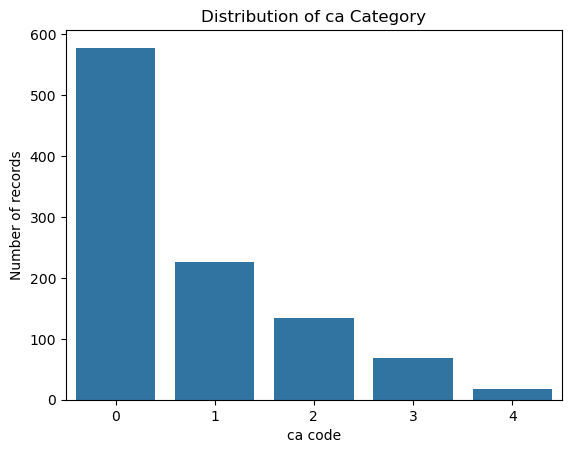

In [198]:
display(data["ca"].value_counts(dropna=False).sort_index().rename_axis("ca category").to_frame("count"))
sns.countplot(data=data, x="ca", order=sorted(data["ca"].dropna().unique()))
plt.title("Distribution of ca Category")
plt.xlabel("ca code")
plt.ylabel("Number of records")
plt.show()

# Medium-Level Questions

## Medium Q1. Is age correlated with cholesterol?

Pearson correlation between age and cholesterol: 0.220


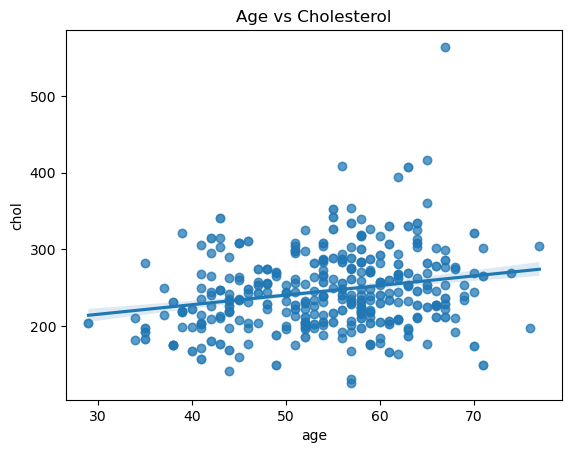

In [199]:
corr = data[["age", "chol"]].corr().iloc[0, 1]
print(f"Pearson correlation between age and cholesterol: {corr:.3f}")

sns.regplot(data=data, x="age", y="chol", scatter_kws={"alpha": 0.35})
plt.title("Age vs Cholesterol")
plt.show()

## Medium Q2. How does chest-pain category vary across age groups?

cp,0,1,2,3
age_group,,,,
≤39,15,11,24,7
40–49,94,62,72,9
50–59,210,72,110,30
60–69,163,13,68,31
70+,15,9,10,0


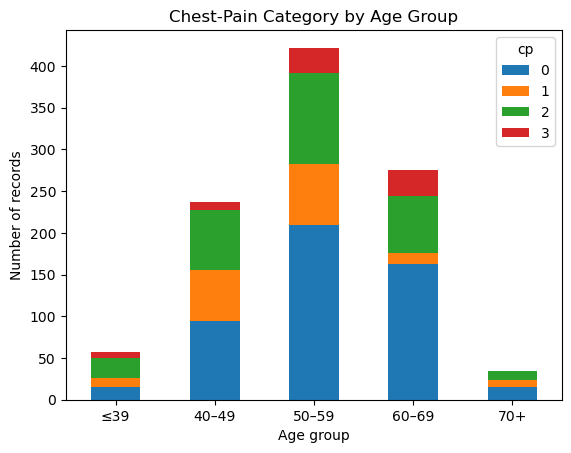

In [200]:
bins = [0, 39, 49, 59, 69, 120]
labels = ["≤39", "40–49", "50–59", "60–69", "70+"]
data["age_group"] = pd.cut(data["age"], bins=bins, labels=labels, include_lowest=True)

age_cp = pd.crosstab(data["age_group"], data["cp"])
display(age_cp)

age_cp.plot(kind="bar", stacked=True)
plt.title("Chest-Pain Category by Age Group")
plt.xlabel("Age group")
plt.ylabel("Number of records")
plt.xticks(rotation=0)
plt.show()

## Medium Q3. Compare `thalach` for records with and without exercise-induced angina.

,count,mean,median,std
exang,,,,
0,680,155.34,159.5,21.51
1,345,136.84,138.0,20.83


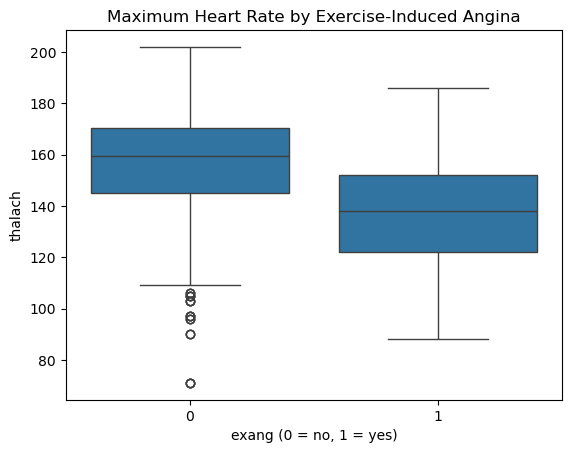

In [201]:
display(data.groupby("exang")["thalach"].agg(["count", "mean", "median", "std"]).round(2))

sns.boxplot(data=data, x="exang", y="thalach")
plt.title("Maximum Heart Rate by Exercise-Induced Angina")
plt.xlabel("exang (0 = no, 1 = yes)")
plt.show()

## Medium Q4. Is resting blood pressure different between sex groups? (Welch's t-test)

In [202]:
from scipy.stats import ttest_ind

group0 = data.loc[data["sex"] == 0, "trestbps"].dropna()
group1 = data.loc[data["sex"] == 1, "trestbps"].dropna()
t_stat, p_value = ttest_ind(group0, group1, equal_var=False)

print(f"Mean BP for sex=0: {group0.mean():.2f}")
print(f"Mean BP for sex=1: {group1.mean():.2f}")
print(f"Welch t-statistic: {t_stat:.3f}")
print(f"p-value: {p_value:.4f}")
print("Interpretation: p < 0.05 suggests evidence of a difference in group means; it does not explain why.")

Mean BP for sex=0: 133.70
Mean BP for sex=1: 130.70
Welch t-statistic: 2.369
p-value: 0.0182
Interpretation: p < 0.05 suggests evidence of a difference in group means; it does not explain why.


## Medium Q5. How does fasting blood sugar (`fbs`) relate to `target`?

target,0,1
fbs,,
0,47.82,52.18
1,53.59,46.41


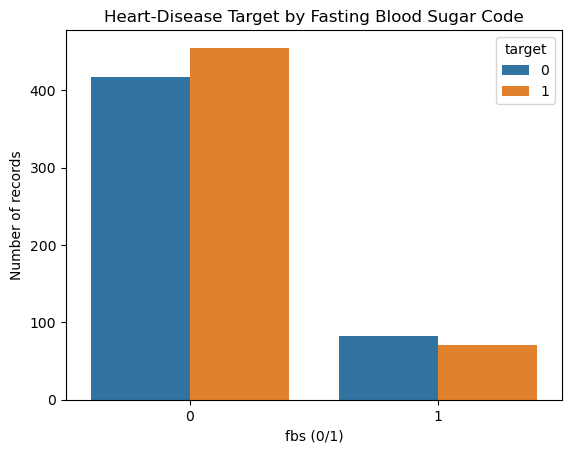

In [203]:
fbs_target = pd.crosstab(data["fbs"], data["target"], normalize="index") * 100
display(fbs_target.round(2))

sns.countplot(data=data, x="fbs", hue="target")
plt.title("Heart-Disease Target by Fasting Blood Sugar Code")
plt.xlabel("fbs (0/1)")
plt.ylabel("Number of records")
plt.show()

## Medium Q6. How does `ca` vary by heart-disease target?

target,0,1
ca,,
0,28.20,71.80
1,70.80,29.20
2,84.33,15.67
3,86.96,13.04
4,16.67,83.33


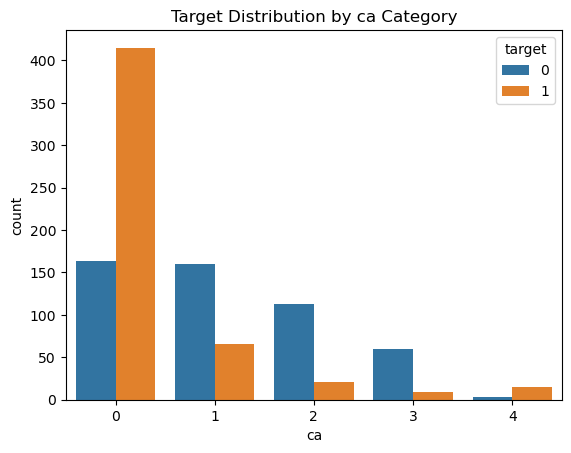

In [204]:
display(pd.crosstab(data["ca"], data["target"], normalize="index").mul(100).round(2))

sns.countplot(data=data, x="ca", hue="target")
plt.title("Target Distribution by ca Category")
plt.show()

## Medium Q7. Compare `oldpeak` across chest-pain categories.

,count,mean,median
cp,,,
0,497,1.44,1.2
1,167,0.32,0.0
2,284,0.78,0.5
3,77,1.38,1.2


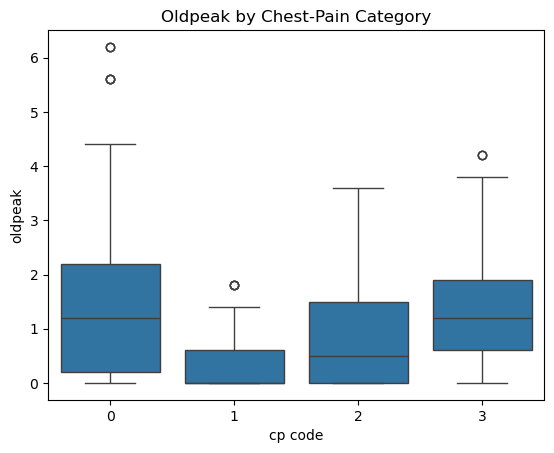

In [205]:
display(data.groupby("cp")["oldpeak"].agg(["count", "mean", "median"]).round(2))

sns.boxplot(data=data, x="cp", y="oldpeak")
plt.title("Oldpeak by Chest-Pain Category")
plt.xlabel("cp code")
plt.show()

## Medium Q8. What is the `thal` distribution among records with and without heart disease?

target,0,1
thal,,
0,0.80,0.57
1,8.62,3.99
2,26.45,78.33
3,64.13,17.11


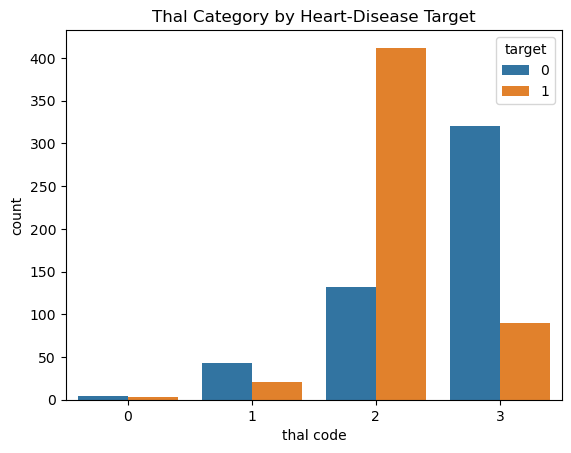

In [206]:
thal_target = pd.crosstab(data["thal"], data["target"], normalize="columns") * 100
display(thal_target.round(2))

sns.countplot(data=data, x="thal", hue="target")
plt.title("Thal Category by Heart-Disease Target")
plt.xlabel("thal code")
plt.show()

## Medium Q9. What combinations of `cp`, `fbs`, `exang`, and `thal` are common when `target = 1`?

In [207]:
positive = data.loc[data["target"] == 1]
combos = (positive.groupby(["cp", "fbs", "exang", "thal"])
          .size().sort_values(ascending=False).head(10).rename("count").reset_index())
display(combos)

,cp,fbs,exang,thal,count
0,2,0,0,2,133
1,1,0,0,2,97
2,0,0,0,2,73
3,2,1,0,2,32
4,2,0,0,3,19
5,0,0,1,2,18
6,3,0,0,2,16
7,1,0,0,3,15
8,2,0,1,2,13
9,3,0,0,3,10


## Medium Q10. Compare clinical measures between target groups.

age              trestbps                  chol               thalach               oldpeak             
         mean median   std     mean median    std    mean median    std    mean median    std    mean median   std
target                                                                                                            
0       56.57   58.0  7.91   134.11  130.0  18.58  251.29  249.0  49.56  139.13  142.0  22.57    1.60    1.4  1.29
1       52.41   52.0  9.63   129.25  130.0  16.11  240.98  234.0  53.01  158.59  161.5  19.10    0.57    0.2  0.77

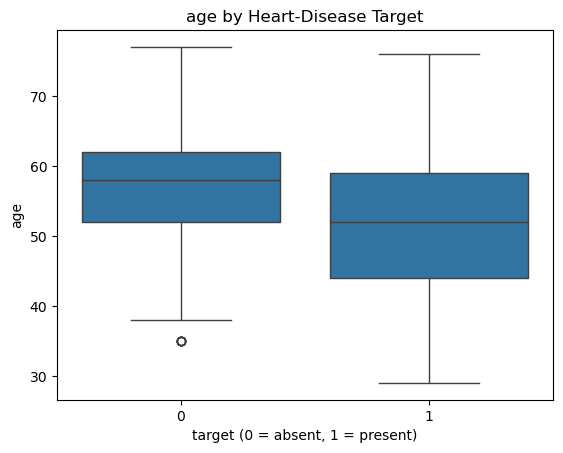

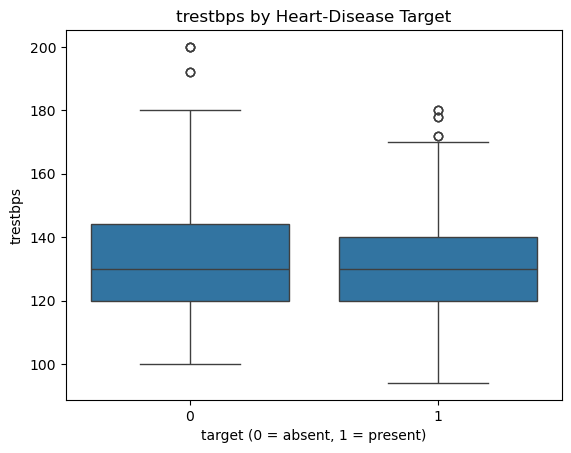

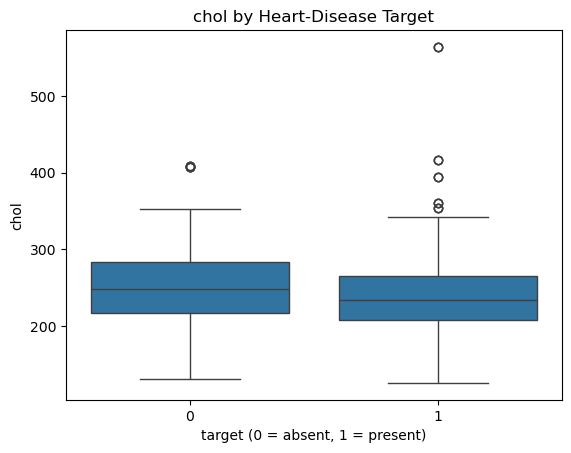

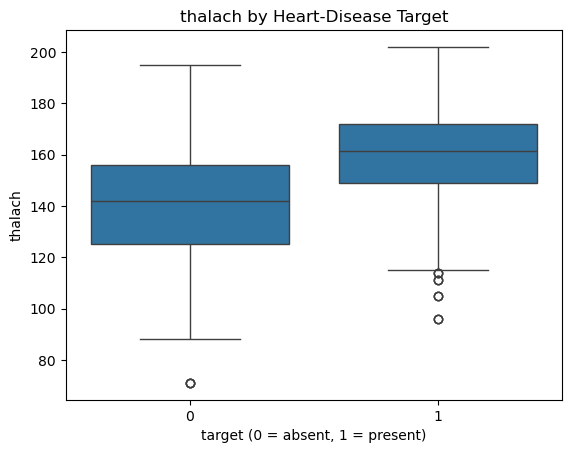

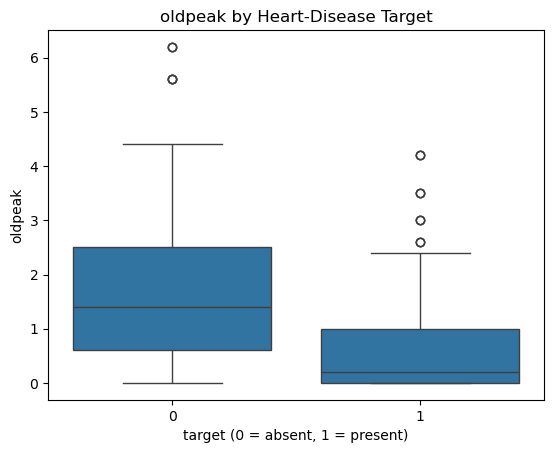

In [208]:
measures = ["age", "trestbps", "chol", "thalach", "oldpeak"]
display(data.groupby("target")[measures].agg(["mean", "median", "std"]).round(2))

for col in measures:
    sns.boxplot(data=data, x="target", y=col)
    plt.title(f"{col} by Heart-Disease Target")
    plt.xlabel("target (0 = absent, 1 = present)")
    plt.show()

# Advanced-Level Questions

## Advanced Q1. Explore combined age, cholesterol, and blood-pressure patterns.

In [209]:
data["age_band"] = pd.cut(data["age"], bins=[0, 44, 54, 64, 120],
                          labels=["≤44", "45–54", "55–64", "65+"])
data["chol_band"] = pd.cut(data["chol"], bins=[0, 199, 239, 1000],
                           labels=["≤199", "200–239", "240+"])
data["bp_band"] = pd.cut(data["trestbps"], bins=[0, 119, 129, 139, 1000],
                         labels=["≤119", "120–129", "130–139", "140+"])

risk_pattern = (data.groupby(["age_band", "chol_band", "bp_band"], observed=False)
                .agg(records=("target", "size"), target_rate=("target", "mean"))
                .reset_index())
risk_pattern["target_rate_pct"] = (risk_pattern["target_rate"] * 100).round(2)
display(risk_pattern.sort_values(["records", "target_rate_pct"], ascending=[False, False]).head(20))

,age_band,chol_band,bp_band,records,target_rate,target_rate_pct
35,55–64,240+,140+,96,0.260417,26.04
34,55–64,240+,130–139,60,0.316667,31.67
33,55–64,240+,120–129,57,0.280702,28.07
22,45–54,240+,130–139,47,0.851064,85.11
21,45–54,240+,120–129,46,0.543478,54.35
31,55–64,200–239,140+,44,0.386364,38.64
16,45–54,200–239,≤119,39,0.589744,58.97
47,65+,240+,140+,38,0.578947,57.89
30,55–64,200–239,130–139,32,0.406250,40.62
29,55–64,200–239,120–129,29,0.482759,48.28


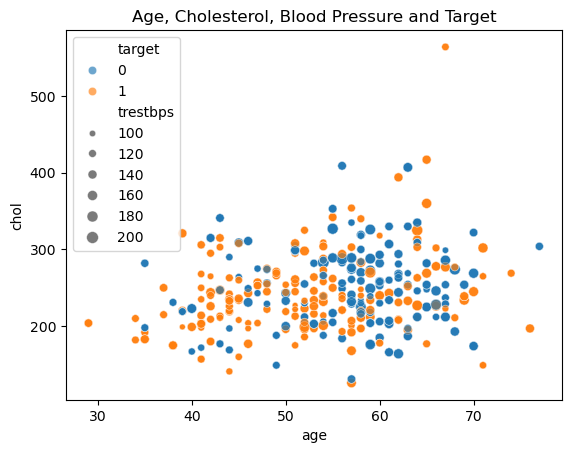

In [210]:
sns.scatterplot(data=data, x="age", y="chol", hue="target", size="trestbps", alpha=0.65)
plt.title("Age, Cholesterol, Blood Pressure and Target")
plt.show()

## Advanced Q2. Which individual numeric feature has the strongest correlation with `target`?

,correlation_with_target
oldpeak,-0.438441
exang,-0.438029
cp,0.434854
thalach,0.422895
ca,-0.382085
slope,0.345512
thal,-0.337838
sex,-0.279501
age,-0.229324
trestbps,-0.138772


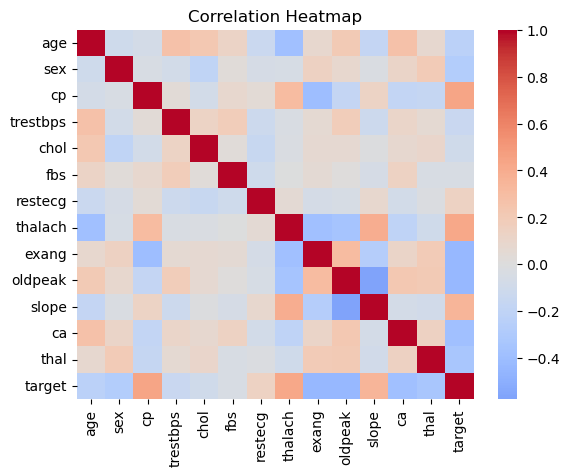

In [211]:
numeric_cols = data.select_dtypes(include="number").columns
target_corr = data[numeric_cols].corr(numeric_only=True)["target"].drop("target")
display(target_corr.reindex(target_corr.abs().sort_values(ascending=False).index).to_frame("correlation_with_target"))

sns.heatmap(data[numeric_cols].corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

## Advanced Q3. Build a logistic-regression model using the available features.

In [212]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score

features = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
            "thalach", "exang", "oldpeak", "slope", "ca", "thal"]
X = data[features].copy()
y = data["target"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(max_iter=2000, random_state=42))
])
model.fit(X_train, y_train)
pred = model.predict(X_test)
prob = model.predict_proba(X_test)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, pred):.3f}")
print(f"ROC-AUC: {roc_auc_score(y_test, prob):.3f}")
print("\nClassification report:")
print(classification_report(y_test, pred, zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(y_test, pred))

Accuracy: 0.810
ROC-AUC: 0.930

Classification report:
              precision    recall  f1-score   support

           0       0.89      0.70      0.78       100
           1       0.76      0.91      0.83       105

    accuracy                           0.81       205
   macro avg       0.82      0.81      0.81       205
weighted avg       0.82      0.81      0.81       205

Confusion matrix:
[[70 30]
 [ 9 96]]


## Advanced Q4. How does `slope` vary by chest-pain category?

slope,0,1,2
cp,,,
0,42,292,163
1,8,41,118
2,15,110,159
3,9,39,29


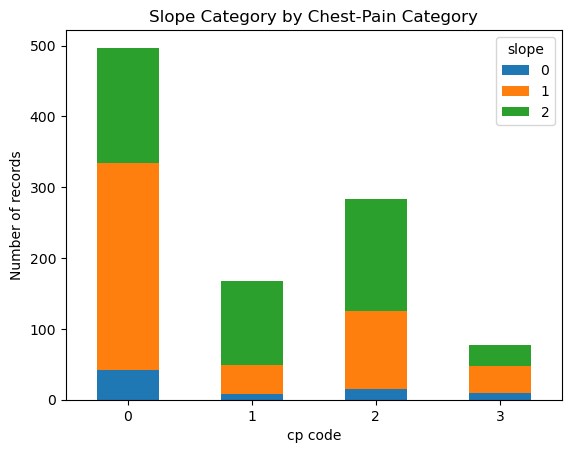

In [213]:
slope_cp = pd.crosstab(data["cp"], data["slope"])
display(slope_cp)

slope_cp.plot(kind="bar", stacked=True)
plt.title("Slope Category by Chest-Pain Category")
plt.xlabel("cp code")
plt.ylabel("Number of records")
plt.xticks(rotation=0)
plt.show()

## Advanced Q5. Calculate survival rates by `thal`.

,target_1_percentage
thal,
0,42.86
1,32.81
2,75.74
3,21.95


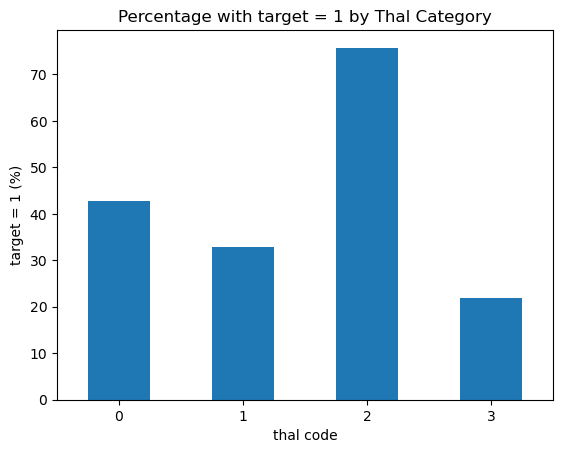

In [214]:
thal_target_rate = data.groupby("thal")["target"].mean().mul(100).round(2)
display(thal_target_rate.rename("target_1_percentage").to_frame())

thal_target_rate.plot(kind="bar")
plt.title("Percentage with target = 1 by Thal Category")
plt.xlabel("thal code")
plt.ylabel("target = 1 (%)")
plt.xticks(rotation=0)
plt.show()

## Save cleaned data

In [215]:
df.to_csv("heart_cleaned.csv", index=False)
print("heart_cleaned.csv")

heart_cleaned.csv
